In [ ]:
import sys

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    '/600 news with valid hoax label.csv',
    sep=';',
    encoding='latin1'
)
print("Ukuran dataset:", df.shape)
df.head()

Ukuran dataset: (600, 2)


,berita,tagging
0,"Jakarta, Di jejaring sosial, banyak beredar in...",Valid
1,Isu bahwa ikan lele mengandung sel kanker di j...,Valid
2,Bagi penikmat kuliner dengan bahan dasar ikan ...,Valid
3,Ikan lele merupakan salah satu makanan favorit...,Valid
4,Ikan lele merupakan bahan makanan yang cukup p...,Valid


In [ ]:
df.info()
print(df['tagging'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   berita   600 non-null    object
 1   tagging  600 non-null    object
dtypes: object(2)
memory usage: 9.5+ KB
tagging
Valid    372
Hoax     228
Name: count, dtype: int64


In [ ]:
!pip install Sastrawi

In [ ]:
import re
import nltk
import pandas as pd

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from nltk.corpus import stopwords

nltk.download('stopwords')

# Membuat stemmer
factory = StemmerFactory()
stemmer = factory.create_stemmer()

# Mengambil stopwords
stop_words = set(stopwords.words('indonesian'))

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()

    words = text.split()
    words = [word for word in words if word not in stop_words]
    words = [stemmer.stem(word) for word in words]

    return ' '.join(words)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
from tqdm.auto import tqdm

tqdm.pandas()

df['berita_clean'] = df['berita'].progress_apply(
    preprocess_text
)

print("Preprocessing selesai!")

  0%|          | 0/600 [00:00<?, ?it/s]

Preprocessing selesai!


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X = tfidf.fit_transform(df['berita_clean'])

print("Ukuran fitur:", X.shape)

Ukuran fitur: (600, 5000)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Mengubah label menjadi angka
le = LabelEncoder()
y = le.fit_transform(df['tagging'])

# Membagi data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data training:", X_train.shape)
print("Data testing:", X_test.shape)

Data training: (480, 5000)
Data testing: (120, 5000)


In [ ]:
from sklearn.linear_model import LogisticRegression

# Membuat model
model = LogisticRegression(max_iter=1000)

# Melatih model
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

Accuracy: 70.0 %

Classification Report:
              precision    recall  f1-score   support

        Hoax       0.73      0.35      0.47        46
       Valid       0.69      0.92      0.79        74

    accuracy                           0.70       120
   macro avg       0.71      0.63      0.63       120
weighted avg       0.71      0.70      0.67       120



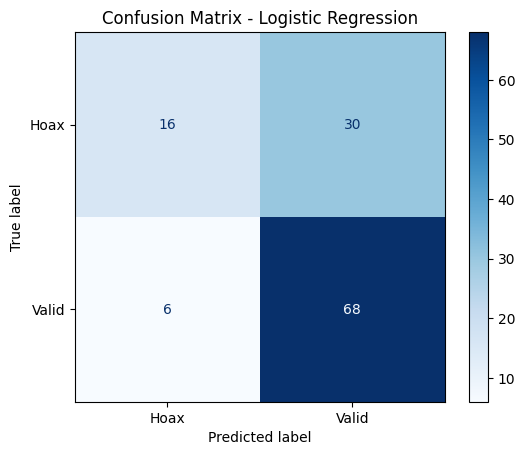

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Prediksi data testing
y_pred = model.predict(X_test)

# Menghitung akurasi
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=le.classes_
))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le.classes_
)

disp.plot(cmap='Blues')
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

Accuracy: 74.17 %
              precision    recall  f1-score   support

        Hoax       0.65      0.72      0.68        46
       Valid       0.81      0.76      0.78        74

    accuracy                           0.74       120
   macro avg       0.73      0.74      0.73       120
weighted avg       0.75      0.74      0.74       120



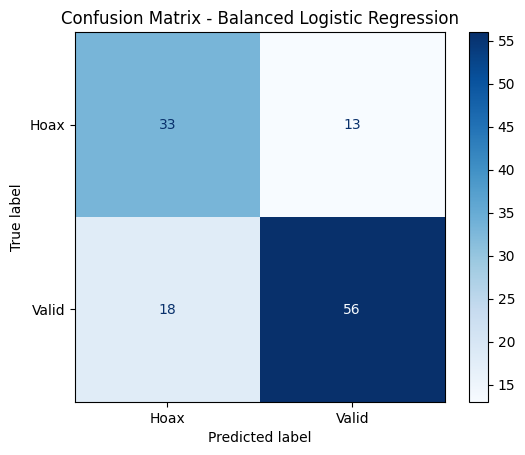

In [ ]:
model_balanced = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

model_balanced.fit(X_train, y_train)

y_pred_balanced = model_balanced.predict(X_test)

print("Accuracy:",
      round(accuracy_score(y_test, y_pred_balanced) * 100, 2), "%")

print(classification_report(
    y_test,
    y_pred_balanced,
    target_names=le.classes_
))

cm_balanced = confusion_matrix(y_test, y_pred_balanced)

ConfusionMatrixDisplay(
    confusion_matrix=cm_balanced,
    display_labels=le.classes_
).plot(cmap='Blues')

plt.title("Confusion Matrix - Balanced Logistic Regression")
plt.show()

In [ ]:
import joblib

joblib.dump(model_balanced, 'logistic_regression_model.pkl')
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')
joblib.dump(le, 'label_encoder.pkl')

['label_encoder.pkl']

In [ ]:
from google.colab import files

files.download('logistic_regression_model.pkl')
files.download('tfidf_vectorizer.pkl')
files.download('label_encoder.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>